# Anexo B. ¿Por qué 12 variables?

**Proyecto final de Computación Cuántica · ¿De qué raza es?**
Anexo al cuaderno `Proyecto_Final_Razas_QML.ipynb`.

El circuito no recibe las 2 048 características de la ResNet-50 sino $d=12$ variables obtenidas con LDA. En el
cuaderno principal elegimos 12 comparando solo $d=8$, 12 y 16 con una semilla. Aquí lo justificamos con más cuidado:
primero vemos qué valores de $d$ son posibles en este circuito y después barremos todos con tres semillas.

## 1. Qué valores de $d$ son posibles

**El número de qubits está fijo por la lectura.** Leemos la raza como uno de los estados base de los qubits medidos.
Con 37 razas hacen falta $\lceil\log_2 37\rceil = 6$ qubits ($2^6 = 64 \ge 37$), así que el circuito plano tiene
$n = 6$ qubits sin importar cuántas variables entren.

**Cada qubit recibe entre una y tres variables por capa.** La codificación reparte las variables entre los qubits y
alterna $R_Y$, $R_Z$, $R_Y$. Con menos de 6 variables algún qubit se quedaría sin dato, y con más de 18 habría que
repetir rotaciones del mismo eje, que se suman y no aportan nada nuevo. Por eso la clase `QNN` exige
$n \le d \le 3n$, es decir, $6 \le d \le 18$.

**LDA da como máximo $K-1 = 36$ componentes**, así que del lado de los datos el límite sería 36.

**$d = 12 = 2n$ es el caso simétrico.** Cada qubit recibe exactamente una $R_Y$ y una $R_Z$ por capa: dos ejes
distintos, con lo que el dato puede llevar el estado a cualquier punto de la esfera de Bloch. Con $d = 6$ solo hay
$R_Y$ (un eje) y con $d$ entre 13 y 18 algunos qubits reciben tres rotaciones y otros dos.

**El número de parámetros crece con $d$.** El circuito plano tiene $2nL + dL + 1$ parámetros ($2nL$ del *ansatz*,
$dL$ escalas $\alpha$ y la temperatura $\beta$). Con $L=5$: 91 con $d=6$, 121 con $d=12$ y 151 con $d=18$. Lo tenemos
en cuenta al leer los resultados: más $d$ también es más parámetros.

Lo que sigue decide **empíricamente** dentro de ese intervalo.

## Código compartido con el cuaderno principal

Para que los resultados sean comparables, las celdas siguientes se copian **sin cambios** del cuaderno principal
(`Proyecto_Final_Razas_QML.ipynb`): librerías, carga de las características, partición entrenamiento/validación,
la clase `Reductor`, la clase `QNN` y la función `metricas`. Mismas semillas, misma partición y mismos hiperparámetros
(Adam con tasa 0.1 y decaimiento coseno, minibatch de 128, 30 épocas, $\beta_0 = 50$).

Todas las decisiones de este anexo se toman con el conjunto de **validación** (552 fotos). El conjunto de prueba no se usa.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pennylane as qml

import torch, torchvision
from torchvision import transforms as T

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import NearestCentroid, KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV

import qiskit
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED)

# Colores que usamos en todas las figuras: gato / perro / modelos cuánticos / clásicos
C_GATO, C_PERRO, C_QNN, C_CLAS = "#e07a5f", "#3d5a80", "#6a4c93", "#8d99ae"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

# Ponlo en True si solo quieres comprobar que todo corre (pocas épocas, pocas semillas)
MODO_RAPIDO = False

print(f"PennyLane {qml.__version__} | Qiskit {qiskit.__version__} | PyTorch {torch.__version__} | modo rápido: {MODO_RAPIDO}")

PennyLane 0.45.1 | Qiskit 2.6.0 | PyTorch 2.6.0+cu124 | modo rápido: False


In [2]:
DATA = "data"
FEATS = os.path.join(DATA, "features.npz")

def extraer_caracteristicas():
    """Pasa todas las fotos por la ResNet-50 congelada y guarda los vectores de 2048 dimensiones."""
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    net = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
    net.fc = torch.nn.Identity()                 # nos quedamos con la salida del pooling global
    net = net.eval().to(dev)
    tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(),
                    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    salida = {}
    for split in ("trainval", "test"):
        ds = torchvision.datasets.OxfordIIITPet(DATA, split=split, target_types="category",
                                                transform=tf, download=True)
        F, Y = [], []
        with torch.no_grad():
            for x, y in torch.utils.data.DataLoader(ds, batch_size=64):
                F.append(net(x.to(dev)).cpu().numpy()); Y.append(y.numpy())
        salida[f"X_{split}"] = np.vstack(F).astype(np.float32)
        salida[f"y_{split}"] = np.concatenate(Y)
        salida["clases"] = np.array(ds.classes)
    np.savez_compressed(FEATS, **salida)

if not os.path.exists(FEATS):
    t0 = time.time(); extraer_caracteristicas(); print(f"Características extraídas en {time.time()-t0:.0f} s")

d = np.load(FEATS)
X_tv, y_tv, X_te, y_te = d["X_trainval"], d["y_trainval"], d["X_test"], d["y_test"]
nombres = [str(c) for c in d["clases"]]
K = len(nombres)

# La especie de cada raza viene en annotations/list.txt (columnas: imagen, id de raza, especie 1=gato 2=perro, ...)
es_gato = np.zeros(K, dtype=bool)
with open(os.path.join(DATA, "oxford-iiit-pet", "annotations", "list.txt")) as f:
    for linea in f:
        if not linea.startswith("#"):
            _, cid, esp, _ = linea.split(); es_gato[int(cid) - 1] = (esp == "1")
especie = lambda y: (~es_gato[y]).astype(int)                # 0 = gato, 1 = perro, para un vector de razas
print(f"trainval: {X_tv.shape}  test: {X_te.shape}  | razas de gato: {es_gato.sum()}  razas de perro: {(~es_gato).sum()}")

trainval: (3680, 2048)  test: (3669, 2048)  | razas de gato: 12  razas de perro: 25


In [3]:
# Partición estratificada: 85 % entrenamiento / 15 % validación dentro de trainval
idx_tr, idx_va = train_test_split(np.arange(len(y_tv)), test_size=0.15, stratify=y_tv, random_state=SEED)
Xtr, ytr = X_tv[idx_tr], y_tv[idx_tr]
Xva, yva = X_tv[idx_va], y_tv[idx_va]
print(f"entrenamiento={len(ytr)}  validación={len(yva)}  prueba={len(y_te)}")

class Reductor:
    """Estandariza -> PCA, LDA o LDA con shrinkage -> escala a [0, pi]. Todo se ajusta con los datos que se le pasan en fit."""
    def __init__(self, tipo="pca", d=12):
        # tipo: "pca", "lda" o "lda_s" (LDA con shrinkage)
        self.tipo, self.d, self.shrink = ("lda" if tipo.startswith("lda") else tipo), d, tipo == "lda_s"
    def fit(self, X, y):
        self.sc = StandardScaler().fit(X)
        Z = self.sc.transform(X)
        if self.tipo == "pca":
            self.red = PCA(self.d, random_state=SEED).fit(Z)
        else:
            self.pre = PCA(min(256, Z.shape[0] - 1, Z.shape[1]), random_state=SEED).fit(Z)
            lda = (LinearDiscriminantAnalysis(solver="eigen", shrinkage="auto", n_components=self.d) if self.shrink
                   else LinearDiscriminantAnalysis(n_components=self.d))
            self.red = lda.fit(self.pre.transform(Z), y)
        self.ang = MinMaxScaler((0, np.pi)).fit(self._proyecta(X))
        return self
    def _proyecta(self, X):
        Z = self.sc.transform(X)
        if self.tipo == "lda": Z = self.pre.transform(Z)
        return self.red.transform(Z)
    def transform(self, X):
        return self.ang.transform(self._proyecta(X))

entrenamiento=3128  validación=552  prueba=3669


In [4]:
class QNN:
    """Clasificador variacional con data re-uploading (n qubits, d variables, K clases, L capas).

    Se construye y se entrena como en el Lab 7: el circuito es un QNode de PennyLane con interfaz de PyTorch
    (diff_method="backprop") y los parámetros se optimizan con torch.optim.Adam."""

    def __init__(self, n, d, K, L, reupload=True, lectura="probs"):
        self.n, self.d, self.K, self.L = n, d, K, L
        self.reupload, self.lectura = reupload, lectura
        self.nr = max(1, int(np.ceil(np.log2(K))))                 # qubits que se leen
        assert self.nr <= n and n <= d <= 3 * n
        self.vars_q = [list(range(q, d, n)) for q in range(n)]      # variables que entran por cada qubit

        dispositivo = qml.device("default.qubit", wires=n)          # simulador analítico (sin shots), como en el Lab 7

        @qml.qnode(dispositivo, interface="torch", diff_method="backprop")
        def q_probs(x, w, a):                                       # Método A del Lab 7: probabilidades de la base computacional
            self.circuito(x, w, a)
            return qml.probs(wires=range(self.nr))

        @qml.qnode(dispositivo, interface="torch", diff_method="backprop")
        def q_z(x, w, a):                                           # Método B del Lab 7: valores esperados de Pauli Z
            self.circuito(x, w, a)
            return tuple(qml.expval(qml.PauliZ(q)) for q in range(self.n))

        self.q_probs, self.q_z = q_probs, q_z

    # ---------------- el circuito ----------------
    def codifica(self, x, a, l):
        """Feature map de la capa l: cada variable entra como RY o RZ (alternando), multiplicada por su escala alpha."""
        for q in range(self.n):
            for k, j in enumerate(self.vars_q[q]):
                (qml.RY, qml.RZ, qml.RY)[k % 3](a[l, j] * x[..., j], wires=q)

    def ansatz(self, w, l):
        """Bloque entrenable de la capa l, el mismo del Lab 7: RY y RZ en cada qubit y CNOT entre vecinos."""
        for q in range(self.n):
            qml.RY(w[l, q, 0], wires=q)
            qml.RZ(w[l, q, 1], wires=q)
        for q in range(self.n):
            qml.CNOT(wires=[q, (q + 1) % self.n])                   # anillo: el último qubit se conecta con el primero

    def circuito(self, x, w, a):
        for l in range(self.L):
            if self.reupload or l == 0:                             # re-uploading: el dato vuelve a entrar en cada capa
                self.codifica(x, a, l)
            self.ansatz(w, l)

    # ---------------- salida y parámetros ----------------
    def salida(self, p, x):
        """Puntuación (logit) de cada clase para un lote x de forma (B, d)."""
        if self.lectura == "probs":
            return p[2] * self.q_probs(x, p[0], p[1])[:, :self.K]  # beta * P(|c>) para cada clase c
        z = torch.stack(self.q_z(x, p[0], p[1]), dim=1)            # (B, n) valores esperados
        return z @ p[2] + p[3]                                      # la matriz A del Lab 7, pero aprendida

    def inicializa(self, rng, beta0):
        T = lambda v: torch.tensor(v, dtype=torch.float64, requires_grad=True)
        w, a = T(rng.uniform(0, 2 * np.pi, (self.L, self.n, 2))), T(np.ones((self.L, self.d)))
        if self.lectura == "probs":
            return [w, a, T(float(beta0))]
        return [w, a, T(rng.normal(0, 0.5, (self.n, self.K))), T(np.zeros(self.K))]

    @property
    def n_params(self):
        na = self.L * self.d if self.reupload else self.d          # sin re-subida solo cuenta la primera capa
        base = 2 * self.L * self.n + na
        return base + (1 if self.lectura == "probs" else self.n * self.K + self.K)

    # ---------------- inferencia ----------------
    def _lote(self, Z, p, bs, fn):
        p = self.params if p is None else p
        p = [torch.as_tensor(np.asarray(t, dtype=float)) for t in p]
        with torch.no_grad():
            return np.vstack([fn(p, torch.as_tensor(Z[i:i + bs], dtype=torch.float64)).numpy() for i in range(0, len(Z), bs)])

    def predict_proba(self, Z, p=None, bs=1000):
        return self._lote(Z, p, bs, lambda p, x: torch.softmax(self.salida(p, x), dim=1))

    def probs_estados(self, Z, p=None, bs=1000):
        """Probabilidad exacta de cada estado base de los qubits que se leen."""
        return self._lote(Z, p, bs, lambda p, x: self.q_probs(x, p[0], p[1]))

    # ---------------- entrenamiento ----------------
    def fit(self, Ztr, ytr, Zva, yva, epocas=30, batch=128, lr=0.1, beta0=50.0, seed=0, verbose=False):
        rng = np.random.default_rng(seed)
        p = self.inicializa(rng, beta0)
        opt = torch.optim.Adam(p, lr=lr)
        Zt, yt = torch.as_tensor(Ztr, dtype=torch.float64), torch.as_tensor(ytr)
        hist = dict(perdida=[], val_acc=[], val_f1=[])
        mejor_f1, mejor = -1, None
        t0 = time.time()
        for ep in range(epocas):
            for g in opt.param_groups:
                g["lr"] = lr * 0.5 * (1 + np.cos(np.pi * ep / epocas))        # decaimiento coseno
            orden = rng.permutation(len(Zt)); perd = []
            for i in range(0, len(orden), batch):
                b = torch.as_tensor(orden[i:i + batch])
                opt.zero_grad()
                loss = torch.nn.functional.cross_entropy(self.salida(p, Zt[b]), yt[b])
                loss.backward(); opt.step(); perd.append(loss.item())
            pv = self.predict_proba(Zva, p=[t.detach().numpy() for t in p]).argmax(1)
            f1 = f1_score(yva, pv, average="macro")
            hist["perdida"].append(np.mean(perd)); hist["val_acc"].append(accuracy_score(yva, pv)); hist["val_f1"].append(f1)
            if f1 > mejor_f1:                                                   # nos quedamos con la mejor época en validación
                mejor_f1, mejor = f1, [t.detach().numpy().copy() for t in p]
            if verbose and (ep % 5 == 4 or ep == 0):
                print(f"  época {ep+1:02d}  pérdida={hist['perdida'][-1]:.3f}  val_acc={hist['val_acc'][-1]:.3f}  val_F1={f1:.3f}  ({time.time()-t0:.0f} s)")
        self.params, self.hist, self.tiempo = mejor, hist, time.time() - t0
        return self


In [5]:
EPOCAS = 2 if MODO_RAPIDO else 30
SEMILLAS = (0,) if MODO_RAPIDO else (0, 1, 2)
L_PLANO = 5

def metricas(P, y):
    """top-1, top-5, F1 macro, accuracy de especie y fracción de errores que ocurren dentro de la misma especie."""
    pred = P.argmax(1)
    top5 = np.mean((np.argsort(-P, axis=1)[:, :5] == y[:, None]).any(1))
    err = pred != y
    intra = np.mean(especie(pred[err]) == especie(y[err])) if err.any() else np.nan
    return dict(acc=accuracy_score(y, pred), top5=top5, f1_macro=f1_score(y, pred, average="macro"),
                acc_especie=np.mean(especie(pred) == especie(y)), err_misma_especie=intra)


## 2. Barrido de $d$ con el QNN plano

Entrenamos el circuito plano (6 qubits, $L=5$) con LDA y cada valor par de $d$ entre 6 y 18, con tres semillas, y
medimos el F1 macro en validación. Como referencia, una regresión logística con las mismas variables, para todos los
valores pares de $d$ hasta 36 (el máximo de LDA).

Antes, una comprobación: con $d=12$ y la semilla 0 el cuaderno principal obtuvo 0.627 de F1 en validación. Si aquí
sale distinto, es por diferencias de máquina o de versión de PyTorch, y lo decimos.

In [6]:
D_QNN = [6, 8, 10, 12, 14, 16, 18]
D_LOG = list(range(2, 37, 2))
reductores = {dd: Reductor("lda", dd).fit(Xtr, ytr) for dd in sorted(set(D_QNN) | set(D_LOG))}

filas_log = []
for dd in D_LOG:
    R = reductores[dd]
    lr_ = LogisticRegression(max_iter=3000).fit(R.transform(Xtr), ytr)
    filas_log.append({"d": dd, "val_F1_logística": f1_score(yva, lr_.predict(R.transform(Xva)), average="macro")})
tab_log = pd.DataFrame(filas_log).set_index("d")

# Son 21 entrenamientos independientes (7 valores de d × 3 semillas). Los corremos en paralelo, un hilo de PyTorch
# por proceso: con circuitos de 6 qubits, un hilo por modelo es más rápido que varios hilos compitiendo.
from joblib import Parallel, delayed

def entrena(dd, sd, Ztr_, Zva_):
    torch.set_num_threads(1)
    m = QNN(6, dd, K, L_PLANO).fit(Ztr_, ytr, Zva_, yva, epocas=EPOCAS, seed=sd)
    return {"d": dd, "semilla": sd, "parámetros": m.n_params,
            "val_F1": metricas(m.predict_proba(Zva_), yva)["f1_macro"], "seg": m.tiempo}

t0 = time.time()
trabajos = [(dd, sd, reductores[dd].transform(Xtr), reductores[dd].transform(Xva)) for dd in D_QNN for sd in SEMILLAS]
filas_q = Parallel(n_jobs=min(6, os.cpu_count()))(delayed(entrena)(*t) for t in trabajos)
print(f"21 modelos en {time.time() - t0:.0f} s")
for r in filas_q:
    print(f"d={r['d']:2d} semilla {r['semilla']}: val_F1={r['val_F1']:.3f}  ({r['parámetros']} parámetros, {r['seg']:.0f} s)")
r12 = next(r for r in filas_q if r["d"] == 12 and r["semilla"] == 0)
print(f"Comprobación contra el cuaderno principal (d=12, semilla 0): {r12['val_F1']:.3f} aquí, 0.627 allá")
q = pd.DataFrame(filas_q)
tabB = q.groupby("d").agg(parámetros=("parámetros", "first"), F1_media=("val_F1", "mean"), F1_desv=("val_F1", "std"),
                          F1_min=("val_F1", "min"), F1_max=("val_F1", "max"), seg_por_modelo=("seg", "mean"))
tabB["F1_logística"] = tab_log.loc[tabB.index, "val_F1_logística"]
display(tabB.round(3))

21 modelos en 1018 s
d= 6 semilla 0: val_F1=0.493  (91 parámetros, 188 s)
d= 6 semilla 1: val_F1=0.423  (91 parámetros, 187 s)
d= 6 semilla 2: val_F1=0.477  (91 parámetros, 187 s)
d= 8 semilla 0: val_F1=0.519  (101 parámetros, 202 s)
d= 8 semilla 1: val_F1=0.476  (101 parámetros, 195 s)
d= 8 semilla 2: val_F1=0.518  (101 parámetros, 202 s)
d=10 semilla 0: val_F1=0.559  (111 parámetros, 211 s)
d=10 semilla 1: val_F1=0.566  (111 parámetros, 217 s)
d=10 semilla 2: val_F1=0.560  (111 parámetros, 213 s)
d=12 semilla 0: val_F1=0.628  (121 parámetros, 228 s)
d=12 semilla 1: val_F1=0.616  (121 parámetros, 232 s)
d=12 semilla 2: val_F1=0.618  (121 parámetros, 229 s)
d=14 semilla 0: val_F1=0.575  (131 parámetros, 270 s)
d=14 semilla 1: val_F1=0.627  (131 parámetros, 270 s)
d=14 semilla 2: val_F1=0.651  (131 parámetros, 273 s)
d=16 semilla 0: val_F1=0.608  (141 parámetros, 294 s)
d=16 semilla 1: val_F1=0.595  (141 parámetros, 294 s)
d=16 semilla 2: val_F1=0.583  (141 parámetros, 293 s)
d=18 semil

,parámetros,F1_media,F1_desv,F1_min,F1_max,seg_por_modelo,F1_logística
d,,,,,,,
6,91,0.464,0.037,0.423,0.493,187.491,0.767
8,101,0.505,0.024,0.476,0.519,199.945,0.796
10,111,0.562,0.004,0.559,0.566,213.750,0.817
12,121,0.620,0.006,0.616,0.628,229.891,0.834
14,131,0.618,0.039,0.575,0.651,270.951,0.860
16,141,0.595,0.013,0.583,0.608,293.539,0.858
18,151,0.624,0.046,0.578,0.670,320.628,0.879


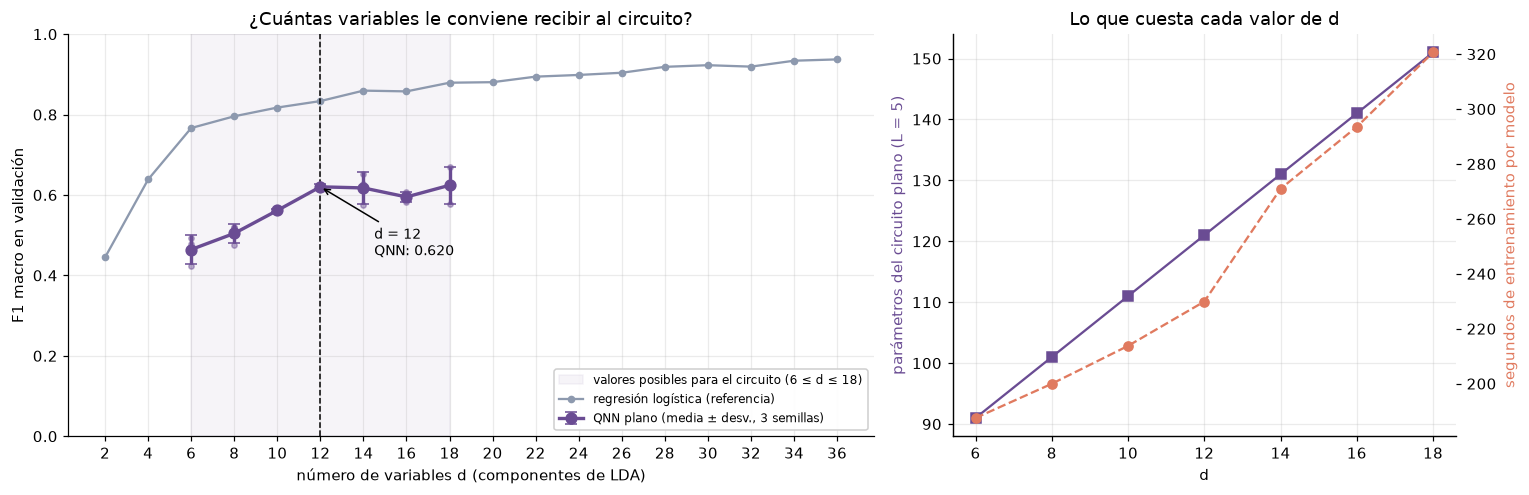

Mayor F1 medio en validación: d = 18 (0.624)


In [7]:
mejor_d = int(tabB.F1_media.idxmax())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})

ax[0].axvspan(6, 18, color=C_QNN, alpha=.06, label="valores posibles para el circuito (6 ≤ d ≤ 18)")
ax[0].plot(tab_log.index, tab_log.val_F1_logística, "o-", color=C_CLAS, ms=4, label="regresión logística (referencia)")
ax[0].errorbar(tabB.index, tabB.F1_media, yerr=tabB.F1_desv, fmt="o-", color=C_QNN, lw=2.2, ms=7, capsize=4,
               label="QNN plano (media ± desv., 3 semillas)")
for dd, s_ in q.groupby("d"):
    ax[0].scatter([dd] * len(s_), s_.val_F1, color=C_QNN, s=12, alpha=.45, zorder=3)
ax[0].axvline(12, color="k", ls="--", lw=1)
ax[0].annotate(f"d = 12\nQNN: {tabB.loc[12, 'F1_media']:.3f}", (12, tabB.loc[12, "F1_media"]),
               xytext=(14.5, tabB.loc[12, "F1_media"] - 0.17), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax[0].set_xlabel("número de variables d (componentes de LDA)"); ax[0].set_ylabel("F1 macro en validación")
ax[0].set_xticks(range(2, 37, 2)); ax[0].set_ylim(0, 1)
ax[0].set_title("¿Cuántas variables le conviene recibir al circuito?")
ax[0].legend(loc="lower right", fontsize=8, framealpha=.95)

ax[1].plot(tabB.index, tabB.parámetros, "s-", color=C_QNN)
ax[1].set_xlabel("d"); ax[1].set_ylabel("parámetros del circuito plano (L = 5)", color=C_QNN)
ax[1].set_xticks(D_QNN)
ax2 = ax[1].twinx(); ax2.plot(tabB.index, tabB.seg_por_modelo, "o--", color=C_GATO)
ax2.set_ylabel("segundos de entrenamiento por modelo", color=C_GATO); ax2.grid(False)
ax[1].set_title("Lo que cuesta cada valor de d")
plt.tight_layout(); plt.show()
print(f"Mayor F1 medio en validación: d = {mejor_d} ({tabB.F1_media.max():.3f})")

In [8]:
# ¿Las diferencias entre los mejores valores de d son mayores que la variación entre semillas?
top = tabB.sort_values("F1_media", ascending=False).head(3)
for dd, r in top.iterrows():
    print(f"d={dd:2d}: {r.F1_media:.3f} ± {r.F1_desv:.3f}  (rango {r.F1_min:.3f}–{r.F1_max:.3f}, {int(r.parámetros)} parámetros)")

d=18: 0.624 ± 0.046  (rango 0.578–0.670, 151 parámetros)
d=12: 0.620 ± 0.006  (rango 0.616–0.628, 121 parámetros)
d=14: 0.618 ± 0.039  (rango 0.575–0.651, 131 parámetros)


## 3. Qué nos dicen los resultados

**La comprobación sale bien.** Con $d=12$ y la semilla 0 obtenemos 0.628 de F1 en validación, contra 0.627 en el
cuaderno principal.

**Hasta $d=12$, más variables ayudan claramente.** El F1 medio sube de 0.464 ($d=6$) a 0.505, 0.562 y 0.620 ($d=12$), y
cada paso es mucho mayor que la variación entre semillas. Con $d=6$ cada qubit recibe una sola rotación $R_Y$ por capa,
y se nota.

**De $d=12$ en adelante la curva se aplana.** Las medias son 0.620 ($d=12$), 0.618 ($d=14$), 0.595 ($d=16$) y 0.624
($d=18$). El valor más alto en promedio es $d=18$, pero solo por 0.004, y sus tres semillas van de 0.578 a 0.670; las de
$d=14$, de 0.575 a 0.651. Con tres semillas y 552 fotos de validación, **$d=12$, 14 y 18 están empatados**: no podemos
decir que uno sea mejor que otro.

**Entre los empatados, $d=12$ es la mejor elección.** Usamos la regla habitual de "una desviación estándar" para elegir
un hiperparámetro: entre los valores cuyo rendimiento no se distingue del mejor, se toma el más sencillo. El error
estándar de la media de $d=18$ es $0.046/\sqrt{3}\approx0.027$, así que todo $d$ con media de al menos
$0.624-0.027=0.597$ está empatado con él. El menor $d$ que lo cumple es **12** ($d=10$ queda en 0.562). Además, $d=12$:

* es **el más estable**: desviación de 0.006 entre semillas, contra 0.039 con $d=14$ y 0.046 con $d=18$. Con $d=12$ el
  resultado casi no depende de la inicialización;
* tiene **menos parámetros** (121, contra 131 y 151) y se entrena más rápido;
* es el caso **simétrico** del circuito, $d=2n$: cada qubit recibe exactamente una $R_Y$ y una $R_Z$ por capa. Con
  $d>12$ algunos qubits reciben tres rotaciones y otros dos, y el circuito deja de tratar igual a todas las variables,
  lo que podría explicar la mayor variación entre semillas (no lo comprobamos).

**El límite es del circuito, no de la información.** La regresión logística sigue mejorando con más variables (0.834 con
$d=12$, 0.879 con $d=18$ y cerca de 0.94 con $d=36$). Las variables 13 a 18 sí traen información útil sobre la raza, pero este
circuito de 6 qubits no la aprovecha. Para usar más variables habría que cambiar el circuito (más qubits o una
codificación distinta), no solo el preprocesamiento.

**Limitaciones.** Tres semillas, una sola partición y 552 fotos de validación. Los tiempos de entrenamiento de la
gráfica son de procesos corriendo en paralelo, así que sirven para comparar entre valores de $d$ pero no como tiempo
absoluto.